In [1]:
from pathlib import Path
import os
import sys
import json
import csv

ROOT = Path.cwd()
if not (ROOT / "data" / "manifests").exists():
    ROOT = Path(r"D:\\FILE AND TASK\\TA")
assert (ROOT / "data" / "manifests").exists(), ROOT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["MPLBACKEND"] = "Agg"

try:
    from IPython.display import display, Image
except ImportError:
    def display(item): print(item)
    class Image:
        def __init__(self, filename): self.filename = filename

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project:", ROOT)
print("Kernel:", sys.executable)


def show_json(path):
    print(path)
    print(json.dumps(json.loads(path.read_text(encoding="utf-8")), ensure_ascii=False, indent=2))


def show_csv(path, rows=30):
    frame = pd.read_csv(path, low_memory=False)
    print(path, "|", len(frame), "baris")
    display(frame if len(frame) <= rows else pd.concat([frame.head(rows // 2), frame.tail(rows // 2)]))
    if len(frame) > rows:
        print("Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.")
    return frame


Project: D:\FILE AND TASK\TA
Kernel: c:\Users\Fabio\AppData\Local\Programs\Python\Python314\python.exe


In [2]:
# Kode eksperimen berasal dari scripts/run_e3_open_set.py dan ditempatkan langsung di notebook ini.
# Tidak ada pemanggilan subprocess atau eksekusi file runner eksternal.
# Entry point CLI sengaja tidak dipanggil otomatis agar artefak valid tidak tertimpa.
__file__ = str(ROOT / "scripts" / "run_e3_open_set.py")

"""Run E3: frozen open-set threshold calibration and noise transfer.

E3 consumes a completed E2 run explicitly.  Thresholds are selected only from
the separate calibration split and then frozen for every test condition.  No
global threshold configuration or prior experiment output is overwritten.
"""


import argparse
import hashlib
import json
import os
import sys
from datetime import datetime, timezone
from pathlib import Path

os.environ["MPLBACKEND"] = "Agg"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from src.calibrate_threshold import calibrate_threshold_tau, evaluate_open_set_with_frozen_tau
from src.e3_alignment import align_known_noisy_scores
from src.embeddings import AudioRepresentationExtractor, R3_CONTROL_VERSION
from src.mix_noise import mix_audio_at_snr
from src.preprocess import preprocess_audio

MANIFEST = ROOT / "data" / "manifests" / "dataset_split.csv"
UNKNOWN_MANIFEST = ROOT / "data" / "manifests" / "unknown_open_set_manifest.csv"
FEATURES = ROOT / "results" / "features"
OUTPUT_ROOT = ROOT / "results" / "reproductions"
REPRESENTATIONS = ("R0", "R1", "R2", "R3")
SNR_LEVELS = (20, 10, 0, -5)
DIMENSIONS = {"R0": 40, "R1": 2048, "R2": 1024, "R3": 40}
UNKNOWN_NOISE_SEED_BASE = 30_261_012


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def atomic_json(path: Path, value: object, replace: bool = False) -> None:
    if path.exists() and not replace:
        raise FileExistsError(path)
    temporary = path.with_name(path.name + ".tmp")
    if temporary.exists():
        raise FileExistsError(temporary)
    with temporary.open("xb") as output:
        encoded = (json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n").encode("utf-8")
        output.write(encoded)
        output.flush()
        os.fsync(output.fileno())
    temporary.replace(path)


def atomic_csv(frame: pd.DataFrame, path: Path) -> None:
    if path.exists():
        raise FileExistsError(path)
    temporary = path.with_name(path.name + ".tmp")
    if temporary.exists():
        raise FileExistsError(temporary)
    with temporary.open("x", newline="", encoding="utf-8") as output:
        frame.to_csv(output, index=False)
        output.flush()
        os.fsync(output.fileno())
    temporary.replace(path)


def load_splits() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    known = pd.read_csv(MANIFEST, dtype={"recording_id": str})
    unknown = pd.read_csv(UNKNOWN_MANIFEST, dtype={"unknown_id": str})
    gallery = known.loc[known.split_role.eq("gallery")].reset_index(drop=True)
    calibration_known = known.loc[known.split_role.eq("calibration")].reset_index(drop=True)
    query_known = known.loc[known.split_role.eq("query_clean")].reset_index(drop=True)
    calibration_unknown = unknown.loc[unknown.split_role.eq("unknown_calibration")].reset_index(drop=True)
    test_unknown = unknown.loc[unknown.split_role.eq("unknown_test")].reset_index(drop=True)
    if (len(gallery), len(calibration_known), len(query_known), len(calibration_unknown), len(test_unknown)) != (673, 232, 311, 233, 310):
        raise ValueError("Active E3 split counts differ from the validated manifest.")
    all_known_paths = set(known.file_path.astype(str))
    if any(path in all_known_paths for path in unknown.file_path.astype(str)):
        raise ValueError("Known and unknown manifests share an audio path.")
    if set(calibration_unknown.unknown_id).intersection(test_unknown.unknown_id):
        raise ValueError("Unknown calibration/test IDs overlap.")
    return gallery, calibration_known, query_known, calibration_unknown, test_unknown


def load_cache(rep: str, gallery: pd.DataFrame, queries: pd.DataFrame) -> dict[str, np.ndarray]:
    path = FEATURES / f"clean_embeddings_{rep}.npz"
    with np.load(path) as source:
        cache = {key: source[key].copy() for key in source.files}
    if str(cache.get("manifest_sha256", np.array("missing")).item()) != sha256_file(MANIFEST):
        raise ValueError(f"E3 cache {rep} does not match active manifest.")
    if cache["gal_feats"].shape != (len(gallery), DIMENSIONS[rep]) or cache["qry_feats"].shape != (len(queries), DIMENSIONS[rep]):
        raise ValueError(f"E3 cache shape invalid for {rep}.")
    if not np.array_equal(cache["gal_ids"].astype(str), gallery.recording_id.astype(str).to_numpy()):
        raise ValueError(f"E3 gallery cache IDs mismatch for {rep}.")
    if not np.array_equal(cache["qry_ids"].astype(str), queries.recording_id.astype(str).to_numpy()):
        raise ValueError(f"E3 query cache IDs mismatch for {rep}.")
    if rep == "R3" and str(cache.get("r3_control_version", np.array("missing")).item()) != R3_CONTROL_VERSION:
        raise ValueError("E3 R3 cache version mismatch.")
    return cache


def max_scores(vectors: np.ndarray, gallery_vectors: np.ndarray) -> np.ndarray:
    query_normalized = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-8)
    gallery_normalized = gallery_vectors / np.maximum(np.linalg.norm(gallery_vectors, axis=1, keepdims=True), 1e-8)
    return np.max(query_normalized @ gallery_normalized.T, axis=1).astype(np.float64)


def embed_rows(extractor: AudioRepresentationExtractor, rows: pd.DataFrame, id_column: str, namespace: str) -> np.ndarray:
    values = []
    for position, (_, row) in enumerate(rows.iterrows(), start=1):
        audio = preprocess_audio(str(row.file_path))
        value = extractor.extract(audio, item_id=f"{namespace}:{row[id_column]}")
        if value.shape != (DIMENSIONS[extractor.rep_code],) or not np.isfinite(value).all():
            raise ValueError(f"Invalid E3 embedding for {row[id_column]}")
        values.append(value.astype(np.float32, copy=False))
        if position % 50 == 0 or position == len(rows):
            print(f"E3 {extractor.rep_code} {namespace}: {position}/{len(rows)}", flush=True)
    return np.stack(values)


def validate_e2(e2_run: Path, query_known: pd.DataFrame) -> dict:
    metadata = e2_run / "metadata.json"
    identity = e2_run / "run_identity.json"
    if not metadata.is_file() or not identity.is_file():
        raise FileNotFoundError("E2 metadata or identity is missing.")
    info = json.loads(metadata.read_text(encoding="utf-8"))
    if info.get("status") != "complete" or info.get("manifest_sha256") != sha256_file(MANIFEST):
        raise ValueError("E2 is not complete or uses another manifest.")
    for rep in REPRESENTATIONS:
        for suffix in ["Clean", *[f"SNR_{snr}dB" for snr in SNR_LEVELS]]:
            path = e2_run / "raw" / f"{rep}_{suffix}.csv"
            if not path.is_file() or not path.with_suffix(".json").is_file():
                raise FileNotFoundError(f"E2 condition missing: {path}")
            rows = pd.read_csv(path, low_memory=False)
            if len(rows) != len(query_known) or rows.query_id.astype(str).tolist() != query_known.recording_id.astype(str).tolist():
                raise ValueError(f"E2 query alignment invalid: {path}")
    return {"path": str(e2_run.relative_to(ROOT)).replace("\\", "/"), "metadata_sha256": sha256_file(metadata), "identity_sha256": sha256_file(identity)}


def test_rows(rep: str, condition: str, snr: int, known_scores: np.ndarray, unknown_scores: np.ndarray, known_ids: list[str], unknown_ids: list[str], tau: float, known_noise: list[str], unknown_noise: list[str]) -> pd.DataFrame:
    records = []
    for identifier, score, noise in zip(known_ids, known_scores, known_noise):
        records.append({"representation": rep, "condition": condition, "snr_db": snr, "query_id": identifier, "target_type": "known_bird", "ground_truth": 1, "similarity_score": float(score), "frozen_tau": tau, "predicted_accept": int(score >= tau), "noise_file": noise})
    for identifier, score, noise in zip(unknown_ids, unknown_scores, unknown_noise):
        records.append({"representation": rep, "condition": condition, "snr_db": snr, "query_id": identifier, "target_type": "unknown_control", "ground_truth": 0, "similarity_score": float(score), "frozen_tau": tau, "predicted_accept": int(score >= tau), "noise_file": noise})
    return pd.DataFrame(records)


def summarize_test(frame: pd.DataFrame) -> dict[str, float]:
    result = evaluate_open_set_with_frozen_tau(frame.similarity_score.to_numpy(), frame.ground_truth.to_numpy(), float(frame.frozen_tau.iloc[0]))
    result.update({"representation": str(frame.representation.iloc[0]), "condition": str(frame.condition.iloc[0]), "snr_db": int(frame.snr_db.iloc[0])})
    return result


def figure(summary: pd.DataFrame, output: Path) -> None:
    plt.figure(figsize=(8, 5))
    for rep, part in summary.groupby("representation", sort=True):
        noisy = part[part.condition.ne("Clean")].sort_values("snr_db")
        plt.plot(noisy.snr_db, noisy.Recall_at_tau, marker="o", label=rep)
    plt.xlabel("Target SNR (dB)")
    plt.ylabel("Known-query recall at frozen threshold")
    plt.title("E3 threshold transfer")
    plt.grid(alpha=0.3)
    plt.legend(title="Representation")
    plt.tight_layout()
    plt.savefig(output, dpi=180)
    plt.close()


def run(e2_run: Path) -> Path:
    gallery, calibration_known, query_known, calibration_unknown, test_unknown = load_splits()
    e2_reference = validate_e2(e2_run.resolve(), query_known)
    now = datetime.now(timezone.utc)
    output = OUTPUT_ROOT / f"E3_open_set_{now.strftime('%Y%m%dT%H%M%S_%fZ')}"
    output.mkdir(parents=True, exist_ok=False)
    (output / "tables").mkdir()
    (output / "raw").mkdir()
    (output / "figures").mkdir()

    all_calibration = []
    all_test = []
    thresholds = []
    summaries = []
    for rep in REPRESENTATIONS:
        cache = load_cache(rep, gallery, query_known)
        gallery_vectors = cache["gal_feats"]
        extractor = AudioRepresentationExtractor(rep)
        calibration_known_vectors = embed_rows(extractor, calibration_known, "recording_id", "calibration")
        calibration_unknown_vectors = embed_rows(extractor, calibration_unknown, "unknown_id", "unknown_calibration")
        calibration_known_scores = max_scores(calibration_known_vectors, gallery_vectors)
        calibration_unknown_scores = max_scores(calibration_unknown_vectors, gallery_vectors)
        calibration_scores = np.concatenate([calibration_known_scores, calibration_unknown_scores])
        calibration_targets = np.concatenate([np.ones(len(calibration_known_scores), dtype=int), np.zeros(len(calibration_unknown_scores), dtype=int)])
        calibration = calibrate_threshold_tau(calibration_scores, calibration_targets, objective="youden_j")
        tau = float(calibration["tau"])
        thresholds.append({"representation": rep, "frozen_tau": tau, "calibration_auroc": float(roc_auc_score(calibration_targets, calibration_scores)), "calibration_youden_j": float(calibration["youden_j"]), "calibration_f1": float(calibration["f1"]), "calibration_precision": float(calibration["precision"]), "calibration_recall": float(calibration["recall"]), "calibration_fpr": float(calibration["fpr"]), "n_known": len(calibration_known_scores), "n_unknown": len(calibration_unknown_scores)})
        for identifier, score in zip(calibration_known.recording_id.astype(str), calibration_known_scores):
            all_calibration.append({"representation": rep, "query_id": identifier, "split_role": "calibration", "target_type": "known_bird", "ground_truth": 1, "similarity_score": float(score), "frozen_tau": tau, "predicted_accept": int(score >= tau)})
        for identifier, score in zip(calibration_unknown.unknown_id.astype(str), calibration_unknown_scores):
            all_calibration.append({"representation": rep, "query_id": identifier, "split_role": "unknown_calibration", "target_type": "unknown_control", "ground_truth": 0, "similarity_score": float(score), "frozen_tau": tau, "predicted_accept": int(score >= tau)})

        unknown_test_vectors = embed_rows(extractor, test_unknown, "unknown_id", "unknown_test")
        unknown_clean_scores = max_scores(unknown_test_vectors, gallery_vectors)
        e2_clean = pd.read_csv(e2_run / "raw" / f"{rep}_Clean.csv", low_memory=False)
        clean_frame = test_rows(rep, "Clean", 999, e2_clean.max_score.to_numpy(dtype=float), unknown_clean_scores, query_known.recording_id.astype(str).tolist(), test_unknown.unknown_id.astype(str).tolist(), tau, ["None (Clean)"] * len(query_known), ["None (Clean)"] * len(test_unknown))
        all_test.extend(clean_frame.to_dict("records"))
        summaries.append(summarize_test(clean_frame))

        unknown_audio = [preprocess_audio(str(row.file_path)) for _, row in test_unknown.iterrows()]
        for snr in SNR_LEVELS:
            e2_path = e2_run / "raw" / f"{rep}_SNR_{snr}dB.csv"
            known_e2 = align_known_noisy_scores(pd.read_csv(e2_path, low_memory=False).rename(columns={"max_score": "max_similarity_score"}), query_known.recording_id.astype(str).tolist())
            vectors = []
            noise_files = []
            for index, clean in enumerate(unknown_audio):
                noisy, audit = mix_audio_at_snr(clean, snr_db=snr, seed=UNKNOWN_NOISE_SEED_BASE + index, return_audit_info=True)
                vectors.append(extractor.extract(noisy, item_id=f"unknown_test:{test_unknown.iloc[index]['unknown_id']}"))
                noise_files.append(audit["noise_file"])
            unknown_scores = max_scores(np.stack(vectors).astype(np.float32), gallery_vectors)
            noisy_frame = test_rows(rep, f"SNR_{snr}dB", snr, known_e2.max_similarity_score.to_numpy(dtype=float), unknown_scores, query_known.recording_id.astype(str).tolist(), test_unknown.unknown_id.astype(str).tolist(), tau, known_e2.noise_file.astype(str).tolist(), noise_files)
            all_test.extend(noisy_frame.to_dict("records"))
            summaries.append(summarize_test(noisy_frame))
            print(f"E3 {rep} SNR {snr} complete", flush=True)

    calibration_frame = pd.DataFrame(all_calibration)
    test_frame = pd.DataFrame(all_test)
    thresholds_frame = pd.DataFrame(thresholds)
    summary_frame = pd.DataFrame(summaries).sort_values(["representation", "snr_db"], ascending=[True, False])
    atomic_csv(calibration_frame, output / "raw" / "calibration_scores.csv")
    atomic_csv(test_frame, output / "raw" / "test_scores.csv")
    atomic_csv(thresholds_frame, output / "tables" / "frozen_thresholds.csv")
    atomic_csv(summary_frame, output / "tables" / "threshold_transfer.csv")
    figure(summary_frame, output / "figures" / "e3_threshold_transfer_recall.png")
    validation = {"status": "PASS", "calibration_rows": int(len(calibration_frame)), "test_rows": int(len(test_frame)), "thresholds": int(len(thresholds_frame)), "e2_reference": e2_reference, "manifest_sha256": sha256_file(MANIFEST)}
    atomic_json(output / "validation_report.json", validation)
    atomic_json(output / "metadata.json", {"artifact_schema": "e3_open_set_v1", "status": "complete", "created_utc": now.isoformat(), "manifest_sha256": sha256_file(MANIFEST), "unknown_manifest_sha256": sha256_file(UNKNOWN_MANIFEST), "e2_reference": e2_reference, "calibration_protocol": "clean calibration split; empirical ROC Youden J; frozen before test", "noise_seed_rule_unknown_test": "30261012 + unknown_test_index", "r3_control_version": R3_CONTROL_VERSION})
    (output / "README.md").write_text("# E3 — Open-set frozen threshold\n\nThresholds are calibrated only from separate clean calibration data and remain frozen across every test SNR. E2 known-query scores are joined by `query_id`, never CSV row order.\n", encoding="utf-8")
    print(f"E3 complete: {output}")
    return output

print("Kode run_e3_open_set.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.")


Kode run_e3_open_set.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.


D:\FILE AND TASK\TA\results\reproductions\E3_open_set_20261012T022548_802536Z\validation_report.json
{
  "status": "PASS",
  "calibration_rows": 1860,
  "test_rows": 12420,
  "thresholds": 4,
  "e2_reference": {
    "path": "results/reproductions/E2_controlled_20261012T021600_897497Z",
    "metadata_sha256": "d20738a9372987f47d06b1af8fd3d683d43c5d40bc64782c3c360a8010c848da",
    "identity_sha256": "fc721fa85378cdf5c4907467102803523db8c5f2535fefcd7279b23c187522fa"
  },
  "manifest_sha256": "7808cdf057f135aaa193f47e27415318edf46c862c09dee4c7394bc5760e8ed8"
}
D:\FILE AND TASK\TA\results\reproductions\E3_open_set_20261012T022548_802536Z\metadata.json
{
  "artifact_schema": "e3_open_set_v1",
  "status": "complete",
  "created_utc": "2026-10-12T02:25:48.802536+00:00",
  "manifest_sha256": "7808cdf057f135aaa193f47e27415318edf46c862c09dee4c7394bc5760e8ed8",
  "unknown_manifest_sha256": "a7cd0b26e87e1eadcf8cc4fe13257a5c9e3cf80d740d9ff0016e46e5479f3266",
  "e2_reference": {
    "path": "results/

,representation,frozen_tau,calibration_auroc,calibration_youden_j,calibration_f1,calibration_precision,calibration_recall,calibration_fpr,n_known,n_unknown
0,R0,0.995752,0.533225,0.099545,0.301003,0.671642,0.193966,0.094421,232,233
1,R1,0.897416,0.709801,0.372299,0.703252,0.665385,0.745690,0.373391,232,233
2,R2,0.702785,0.759953,0.418843,0.669927,0.774011,0.590517,0.171674,232,233
3,R3,0.488838,0.545194,0.087409,0.445026,0.566667,0.366379,0.278970,232,233


D:\FILE AND TASK\TA\results\reproductions\E3_open_set_20261012T022548_802536Z\tables\threshold_transfer.csv | 20 baris


,frozen_tau,AUROC,AUPRC,F1_at_tau,Precision_at_tau,Recall_at_tau,False_Positive_Rate,total_known_tested,total_unknown_tested,representation,condition,snr_db
0,0.995752,0.546380,0.555039,0.281553,0.574257,0.186495,0.138710,311,310,R0,Clean,999
1,0.995752,0.582683,0.594181,0.350467,0.641026,0.241158,0.135484,311,310,R0,SNR_20dB,20
2,0.995752,0.579592,0.588638,0.341121,0.623932,0.234727,0.141935,311,310,R0,SNR_10dB,10
3,0.995752,0.510455,0.518712,0.089021,0.576923,0.048232,0.035484,311,310,R0,SNR_0dB,0
4,0.995752,0.498009,0.500115,0.018868,0.428571,0.009646,0.012903,311,310,R0,SNR_-5dB,-5
5,0.897416,0.745877,0.717167,0.723227,0.637255,0.836013,0.477419,311,310,R1,Clean,999
6,0.897416,0.753739,0.716154,0.723227,0.637255,0.836013,0.477419,311,310,R1,SNR_20dB,20
7,0.897416,0.742195,0.701591,0.709677,0.652291,0.778135,0.416129,311,310,R1,SNR_10dB,10
8,0.897416,0.699129,0.666391,0.628571,0.658451,0.601286,0.312903,311,310,R1,SNR_0dB,0
9,0.897416,0.649507,0.631850,0.520913,0.637209,0.440514,0.251613,311,310,R1,SNR_-5dB,-5


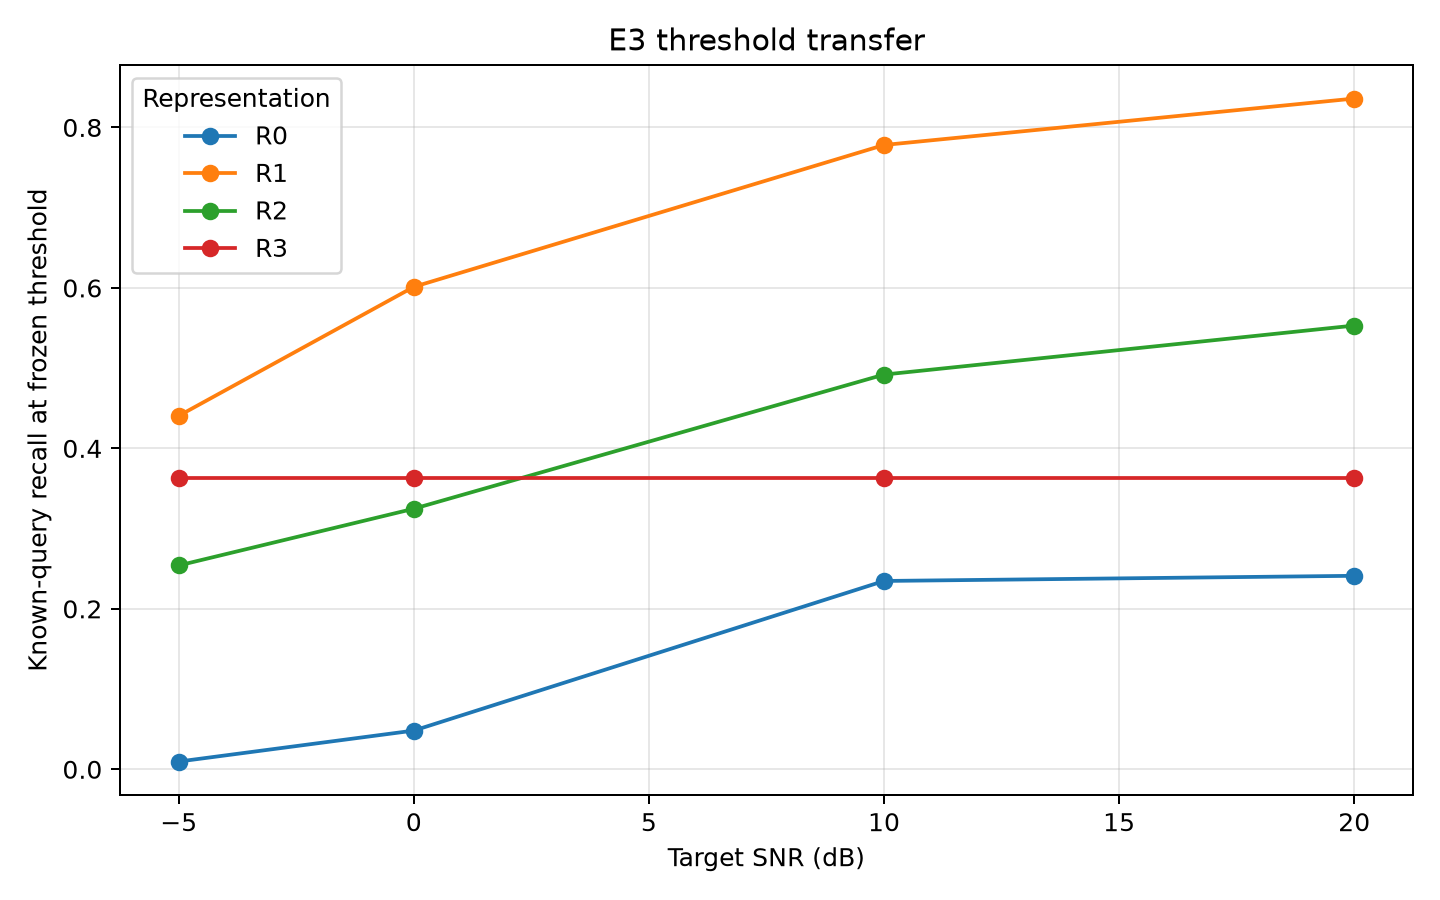

D:\FILE AND TASK\TA\results\reproductions\E3_open_set_20261012T022548_802536Z\raw\calibration_scores.csv | 1860 baris


,representation,query_id,split_role,target_type,ground_truth,similarity_score,frozen_tau,predicted_accept
0,R0,XC431487,calibration,known_bird,1,0.985267,0.995752,0
1,R0,XC431497,calibration,known_bird,1,0.992860,0.995752,0
2,R0,XC431498,calibration,known_bird,1,0.993476,0.995752,0
3,R0,XC571751,calibration,known_bird,1,0.985237,0.995752,0
4,R0,XC604617,calibration,known_bird,1,0.991248,0.995752,0
5,R0,XC610884,calibration,known_bird,1,0.985693,0.995752,0
6,R0,XC1075897,calibration,known_bird,1,0.994978,0.995752,0
7,R0,XC1075899,calibration,known_bird,1,0.990686,0.995752,0
8,R0,XC1075900,calibration,known_bird,1,0.992583,0.995752,0
9,R0,XC376315,calibration,known_bird,1,0.983125,0.995752,0


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.
D:\FILE AND TASK\TA\results\reproductions\E3_open_set_20261012T022548_802536Z\raw\test_scores.csv | 12420 baris


,representation,condition,snr_db,query_id,target_type,ground_truth,similarity_score,frozen_tau,predicted_accept,noise_file
0,R0,Clean,999,XC42472,known_bird,1,0.991959,0.995752,0,None (Clean)
1,R0,Clean,999,XC1098429,known_bird,1,0.991454,0.995752,0,None (Clean)
2,R0,Clean,999,XC20097,known_bird,1,0.994453,0.995752,0,None (Clean)
3,R0,Clean,999,XC20098,known_bird,1,0.992043,0.995752,0,None (Clean)
4,R0,Clean,999,XC214420,known_bird,1,0.996303,0.995752,1,None (Clean)
5,R0,Clean,999,XC236330,known_bird,1,0.985306,0.995752,0,None (Clean)
6,R0,Clean,999,XC34503,known_bird,1,0.979483,0.995752,0,None (Clean)
7,R0,Clean,999,XC151815,known_bird,1,0.994588,0.995752,0,None (Clean)
8,R0,Clean,999,XC152005,known_bird,1,0.984806,0.995752,0,None (Clean)
9,R0,Clean,999,XC152203,known_bird,1,0.992526,0.995752,0,None (Clean)


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.


,representation,condition,snr_db,query_id,target_type,ground_truth,similarity_score,frozen_tau,predicted_accept,noise_file
0,R0,Clean,999,XC42472,known_bird,1,0.991959,0.995752,0,None (Clean)
1,R0,Clean,999,XC1098429,known_bird,1,0.991454,0.995752,0,None (Clean)
2,R0,Clean,999,XC20097,known_bird,1,0.994453,0.995752,0,None (Clean)
3,R0,Clean,999,XC20098,known_bird,1,0.992043,0.995752,0,None (Clean)
4,R0,Clean,999,XC214420,known_bird,1,0.996303,0.995752,1,None (Clean)
...,...,...,...,...,...,...,...,...,...,...
12415,R3,SNR_-5dB,-5,UNK_TEST_NOISE_151,unknown_control,0,0.489959,0.488838,1,Gedung F Frequency/32 kHz Medium Frequency/202...
12416,R3,SNR_-5dB,-5,UNK_TEST_NOISE_152,unknown_control,0,0.424609,0.488838,0,Masjid At-tanwir Amplitudo/32 kHz Medium Ampli...
12417,R3,SNR_-5dB,-5,UNK_TEST_NOISE_153,unknown_control,0,0.535961,0.488838,1,Embung F ITERA Amplitudo/32 kHz High Amplitudo...
12418,R3,SNR_-5dB,-5,UNK_TEST_NOISE_154,unknown_control,0,0.459820,0.488838,0,Masjid At-tanwir Frequency/32 kHz Low Frequenc...


In [3]:
run = ROOT / "results/reproductions/E3_open_set_20261012T022548_802536Z"
show_json(run / "validation_report.json")
show_json(run / "metadata.json")
show_csv(run / "tables/frozen_thresholds.csv")
show_csv(run / "tables/threshold_transfer.csv")
display(Image(filename=str(run / "figures/e3_threshold_transfer_recall.png")))
show_csv(run / "raw/calibration_scores.csv", rows=20)
show_csv(run / "raw/test_scores.csv", rows=20)
